# Optimization by a Genetic Algorithm — evolving a sentence

*Utrecht University Molecular Modelling courses from the [Bonvin lab](https://bonvinlab.org).*

*Adapted from the GeeksforGeeks genetic-algorithm example (geeksforgeeks.org/genetic-algorithms).*

A minimal, self-contained **genetic algorithm (GA)**: a population of random strings is *evolved*
toward a target sentence by imitating natural selection. It is a third flavour of optimization to
sit alongside the **energy-minimization** notebooks (follow the gradient downhill) and the
**Monte Carlo** notebooks (sample by the Metropolis rule) — here the search is driven by
**evolution** of a whole population, and it needs no gradient at all.

## Theory in brief

A genetic algorithm keeps a **population** of candidate solutions and improves it generation by
generation with four ingredients borrowed from biology:

* **Chromosome** — one candidate solution. Here it is a list of characters (a string); the search
  space is every string of the target's length over the allowed alphabet `GENES`.
* **Fitness** — how good a candidate is. Here we use the number of characters that **differ** from
  the target, so **lower is better** and fitness $0$ is the perfect match (the global optimum).
* **Selection** — fitter individuals get to reproduce. We sort by fitness and draw parents from the
  fittest `PARENT_POOL` individuals.
* **Elitism, crossover, mutation** — the next generation is built by (i) copying the fittest
  `ELITE_FRAC` fraction unchanged (**elitism**, so the best is never lost), then (ii) **mating**
  pairs of parents: each child gene is copied from parent 1 or parent 2 (**crossover**) or, with
  probability `MUTATION_RATE`, replaced by a random gene (**mutation**, which maintains diversity
  and lets the search escape dead ends).

Repeating this loop, the population drifts toward ever-fitter strings until one matches the target.

### How big is the search space?
What is optimised here is a **string of characters**. The GA has to find one particular sentence, the
`TARGET` "Structural bioinformatics is the best master course!" (section 3), starting from random
strings of the same length. Each candidate solution is such a string, and the GA minimises its
fitness, the number of characters that differ from the target. To see why this needs a clever
search, count the candidates.

`GENES` holds **85** different characters, so each position of the chromosome has 85 possible
values. The target sentence is $N = 52$ characters long, so there are

$$85^{52} \approx 2 \times 10^{100}$$

possible strings — more than the number of atoms in the observable universe (≈$10^{80}$). Trying them
all, even at a billion strings per second, would take ≈$7 \times 10^{83}$ years (the universe is
≈$1.4 \times 10^{10}$ years old). An exhaustive search grows **exponentially** with the length,
$85^N$: every extra character multiplies the work by 85.

This is even larger than a **factorial** search. $N!$ counts the ways to *order* $N$ given items:
$52! \approx 8 \times 10^{67}$. That is the size of the search space of permutation problems, such
as the travelling-salesman route or rearranging the 52 letters of the target (see swap mutation
below), and it is hopeless to enumerate too. Our problem is harder still, because each position
can also take *any* of the 85 characters.

The GA reaches the target after evaluating only a few tens of thousands of strings (a few hundred
generations × 200 individuals). It can do so because the fitness rewards every correct character
separately: selection keeps the positions that are already right while mutation tries out the
others, so the problem is solved piece by piece instead of all at once.

### The role of the mutation rate
Mutation is a double-edged sword. **Too little** and the population loses diversity and stalls;
**too much** and it never settles — near the optimum, a high per-gene mutation rate keeps breaking
the almost-correct string faster than selection can fix it, producing a long convergence *tail*.
The original example hard-coded `MUTATION_RATE = 0.10`, which converges only after **~1000–3000**
generations; the default here, `0.05`, reaches the target in a **few hundred**. It is the single
most instructive knob in this notebook — try changing it.

### Swap mutation (optional)
A second mutation operator, **swap mutation**, exchanges two genes' *positions* in the chromosome
(`...ba...` → `...ab...`) rather than drawing a new random gene; it is controlled by `SWAP_RATE`
(default `0`). It has a crucial limitation: swapping only **re-orders the genes already present** —
it can never *introduce* a character that is missing. For this positional string-matching problem
that makes it almost useless on its own: with point mutation switched off (`MUTATION_RATE = 0`,
`SWAP_RATE > 0`) the search **never converges**, because there is no way to create the right letters.
So swap mutation only makes sense **in combination with point mutation**, where it adds a little
extra reshuffling. It genuinely pays off on **permutation / ordering problems** (e.g. the
travelling-salesman route), where a solution is an arrangement of a *fixed* set of items and point
mutation would create invalid duplicates.

**How much to swap?** Here we exchange a **single** pair of positions — the smallest, least
destructive swap. The swapped length is effectively a *step-size* knob: swapping longer contiguous
*blocks* only makes things worse for a positional target, because it displaces more genes that were
already correct. Empirically, convergence is unchanged up to a block length of ~2 and then degrades
steadily (a length-5 block roughly doubles the number of generations needed). Big, block-length swaps
are useful mainly on permutation problems (as *inversion* / 2-opt moves), not here.

> **Solutions version — for instructors / checking only.** The values to test in the section 8
> exercise are filled in and the answer blocks are unfolded, so all figures and numbers can be
> compared with the answers. The student version is `Notebooks/GA-optimisation.ipynb`.

## 1. Imports

The GA itself uses only the Python **standard library** (`random`). **matplotlib** is the one
third-party dependency, for the convergence plot and the animation (embedded inline via `jshtml`).
The cell installs matplotlib if it is missing (handy on Google Colab), then imports everything.

In [1]:
# --- Install required packages (works locally, on Colab, and on JupyterLite) ---
%pip install -q matplotlib

import random

import matplotlib.pyplot as plt
import sys, warnings
if sys.platform == "emscripten":   # JupyterLite: its matplotlib build warns on every text label
    warnings.filterwarnings("ignore", message=r"The \w+ parameter as float was deprecated")
from matplotlib.animation import FuncAnimation
from matplotlib import rc

# Show animations inline
rc('animation', html='jshtml')
%matplotlib inline


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /Users/abonvin/haddock_git/haddock3/.venv-3.14/bin/python3.14 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. The `Individual` class

One `Individual` is one candidate solution. It stores its `chromosome` (a list of characters) and
its `fitness`, and knows how to:

* `create_gnome` — build a fresh random chromosome (used to seed the initial population);
* `mate` — combine two parents into a child by crossover + mutation (see the theory above);
* `cal_fitness` — count how many characters differ from the target.

In [2]:
class Individual:
    """One candidate solution in the population."""

    def __init__(self, chromosome):
        self.chromosome = chromosome
        self.fitness = self.cal_fitness()

    @classmethod
    def mutated_genes(cls):
        """A single random gene, used for mutation."""
        return random.choice(GENES)

    @classmethod
    def create_gnome(cls):
        """A fresh random chromosome the length of the target."""
        return [cls.mutated_genes() for _ in range(len(TARGET))]

    def mate(self, par2):
        """Produce one offspring by crossover + mutation."""
        # mutation happens with probability MUTATION_RATE; the parents split the rest equally
        parent_cut = (1.0 - MUTATION_RATE) / 2.0
        child_chromosome = []
        for gp1, gp2 in zip(self.chromosome, par2.chromosome):
            prob = random.random()
            if prob < parent_cut:
                child_chromosome.append(gp1)                    # gene from parent 1
            elif prob < 2 * parent_cut:
                child_chromosome.append(gp2)                    # gene from parent 2
            else:
                child_chromosome.append(self.mutated_genes())   # mutate (diversity)

        # optional swap mutation: exchange two gene positions. This only re-orders genes
        # that are already present (it cannot introduce a missing character), so it never
        # converges alone -- it only helps together with point mutation.
        if SWAP_RATE > 0 and random.random() < SWAP_RATE:
            i = random.randrange(len(child_chromosome))
            j = random.randrange(len(child_chromosome))
            child_chromosome[i], child_chromosome[j] = child_chromosome[j], child_chromosome[i]

        return Individual(child_chromosome)

    def cal_fitness(self):
        """Fitness = number of characters that differ from the target (0 is perfect)."""
        return sum(1 for gs, gt in zip(self.chromosome, TARGET) if gs != gt)

## 3. Parameters

Change any of these and re-run **this cell together with the Run cell just below**. `MUTATION_RATE`
is the one to experiment with first (see the theory); `TARGET` can be any sentence built from the
characters in `GENES`.

| Parameter | Meaning | Typical value |
|---|---|---|
| `TARGET` | the sentence to evolve towards | any string over `GENES` |
| `POPULATION_SIZE` | individuals per generation | 200 |
| `GENES` | the allowed alphabet | letters, digits, punctuation |
| `MUTATION_RATE` | per-gene mutation probability | 0.05 (original used 0.10) |
| `SWAP_RATE` | probability of a position-swap mutation per child (0 = off) | 0.0 |
| `ELITE_FRAC` | fraction copied unchanged each generation | 0.10 |
| `PARENT_POOL` | mating draws parents from the fittest this many | 50 |
| `SEED` | random-number seed (reproducibility) | 100 |
| `MAX_GENERATIONS` | safety cap on the number of generations | 2000 |

In [3]:
TARGET = "Structural bioinformatics is the best master course!"

POPULATION_SIZE = 200

# allowed alphabet (a single string -- must NOT contain a line break)
GENES = (
    "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOP"
    'QRSTUVWXYZ 1234567890,.-;:_!"#%&/()=?@${[]}'
)

MUTATION_RATE   = 0.05   # per-gene mutation probability (original GeeksforGeeks value: 0.10 -> very slow)
SWAP_RATE       = 0.0    # optional swap mutation (exchange two positions); 0 = off. Only useful WITH point mutation
ELITE_FRAC      = 0.10   # fraction of fittest individuals copied unchanged each generation
PARENT_POOL     = 50     # parents are drawn from the fittest this many individuals
SEED            = 100    # random-number seed
MAX_GENERATIONS = 2000   # safety cap

## 4. Run the genetic algorithm

This loop replaces the script's `main()`. It seeds a random population, then each generation sorts
by fitness, keeps the elite, and breeds the rest, recording the **best** and **mean** fitness and
the best string so we can plot and animate the evolution. It stops when the best fitness reaches
$0$ (an exact match) or after `MAX_GENERATIONS`.

In [4]:
def run_ga():
    random.seed(SEED)
    population = [Individual(Individual.create_gnome()) for _ in range(POPULATION_SIZE)]

    best_fit = []; mean_fit = []; best_str = []

    for generation in range(1, MAX_GENERATIONS + 1):
        population.sort(key=lambda ind: ind.fitness)         # fittest (lowest) first
        best = population[0]
        best_fit.append(best.fitness)
        mean_fit.append(sum(ind.fitness for ind in population) / len(population))
        best_str.append("".join(best.chromosome))

        if best.fitness <= 0:                                # exact match found
            break

        n_elite = int(ELITE_FRAC * POPULATION_SIZE)
        new_generation = population[:n_elite]                # elitism
        while len(new_generation) < POPULATION_SIZE:         # breed the rest
            p1 = random.choice(population[:PARENT_POOL])
            p2 = random.choice(population[:PARENT_POOL])
            new_generation.append(p1.mate(p2))
        population = new_generation

        if generation % 20 == 0:
            print("generation %4d   fitness %2d   %s" % (generation, best.fitness, best_str[-1]))

    print("\nConverged at generation %d (fitness %d):" % (len(best_fit), best_fit[-1]))
    print("  ", best_str[-1])
    return best_fit, mean_fit, best_str


best_fit, mean_fit, best_str = run_ga()

generation   20   fitness 21   StructurqTmw-,info{matiys B, eCFEKest ma5t$FhcoursS6
generation   40   fitness 12   Structurq- bizinfoUmatics )( ehP best mast4jtcourseg
generation   60   fitness  5   Structural biXinfo:matics is yhe bGst master coursej
generation   80   fitness  2   Structural bioinformatics is 4he best master courseB
generation  100   fitness  1   Structural bioinformatics is the best master course[
generation  120   fitness  1   Structural bioinformatics is the best master course[
generation  140   fitness  1   Structural bioinformatics is the best master course[
generation  160   fitness  1   Structural bioinformatics is the best master course[

Converged at generation 161 (fitness 0):
   Structural bioinformatics is the best master course!


## 5. Convergence

The **best** fitness in the population (blue) falls to $0$ when the target is found; the **mean**
fitness (orange) settles at a higher value because ongoing mutation keeps injecting errors across
the population. Notice the characteristic shape: a fast initial drop as the easy characters lock in,
then a slower approach as the last few are pinned down (the *tail* set by `MUTATION_RATE`).

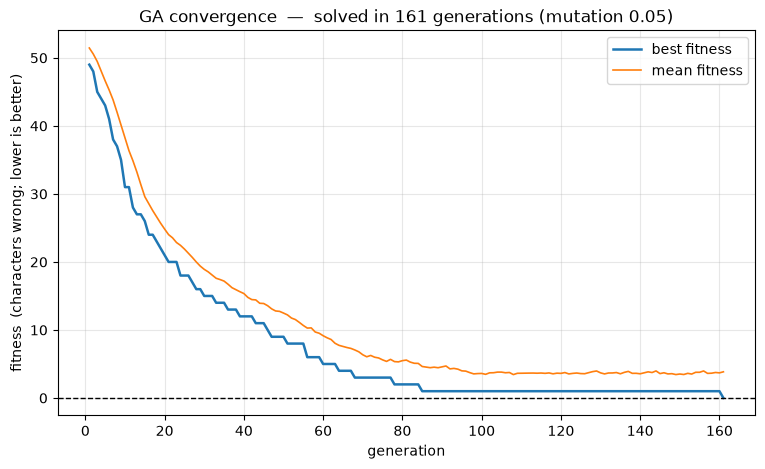

In [5]:
gens = range(1, len(best_fit) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(gens, best_fit, lw=1.8, color="tab:blue",   label="best fitness")
ax.plot(gens, mean_fit, lw=1.2, color="tab:orange", label="mean fitness")
ax.axhline(0, ls="--", color="black", lw=1)
ax.set_xlabel("generation")
ax.set_ylabel("fitness  (characters wrong; lower is better)")
ax.set_title(f"GA convergence  —  solved in {len(best_fit)} generations (mutation {MUTATION_RATE})")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 6. Watch the sentence evolve

The best string in each generation, character by character: **green** where it already matches the
target, **red** where it does not. Red letters turn green as the population evolves.
(Only ~120 frames are shown — adjust `stride`.)

In [6]:
L = len(TARGET)
stride = max(1, len(best_str) // 120)
frames = list(range(0, len(best_str), stride))
if frames[-1] != len(best_str) - 1:
    frames.append(len(best_str) - 1)   # always show the final (solved) frame

fig, ax = plt.subplots(figsize=(13, 1.8))
ax.set_xlim(-0.5, L - 0.5)
ax.set_ylim(-1, 1)
ax.axis('off')

char_texts = []
for i in range(L):
    t = ax.text(i, 0, best_str[0][i], ha='center', va='center',
                family='monospace', fontsize=13, fontweight='bold')
    char_texts.append(t)
gen_title = ax.set_title("")

def update(frame_idx):
    f = frames[frame_idx]
    s = best_str[f]
    for i, t in enumerate(char_texts):
        t.set_text(s[i])
        t.set_color("#1a9850" if s[i] == TARGET[i] else "#d73027")
    gen_title.set_text(f"generation {f+1}   fitness {best_fit[f]}   ({L - best_fit[f]}/{L} correct)")
    return char_texts + [gen_title]

anim = FuncAnimation(fig, update, frames=len(frames), interval=100, blit=False)
plt.close(fig)   # avoid a duplicate static figure
anim

## 7. Genetic algorithms as optimization

This toy problem has an obvious answer (we *know* the target), which makes it perfect for *seeing*
how a genetic algorithm works — but the same machinery optimizes problems where the answer is
**not** known in advance, wherever candidate solutions can be encoded as "chromosomes" and scored by
a fitness function. In structural biology that includes protein and ligand design, and
**docking** (evolving the position/orientation/conformation of a molecule to optimise a binding
score).

Put alongside the other optimizers in this course:

* **Energy minimization** follows the local **gradient** downhill — fast, but it only finds the
  nearest minimum.
* **Monte Carlo / Metropolis** **samples** configurations at a temperature, and can cross barriers.
* **A genetic algorithm** evolves a **whole population** by selection + crossover + mutation. It
  uses **no gradient**, explores many regions at once, and — thanks to mutation and recombination —
  can escape local optima, at the cost of many fitness evaluations.

How fast the GA gets there depends on its parameters. In the exercise below you measure it: the
population size, the mutation rate, the selection pressure and swap mutation. You can also change
`TARGET` (section 3) to your own sentence.

---
## 8. Exercise: what makes the GA converge faster?

The run in section 4 needed a few hundred generations. Is that fast or slow, and which parameters
control it? In this exercise you change one parameter at a time and measure how many **generations**
the GA needs to find the target.

Two things to keep in mind:

* **One run proves nothing.** The GA is random: with another `SEED` the same settings can need twice
  as many generations. Each setting is therefore run with 5 seeds, and we compare the **median**.
* **Generations are not the whole cost.** Every generation evaluates the fitness of the whole
  population, so the real amount of work is **generations × population size** (the number of
  fitness evaluations). Keep that in mind when you compare population sizes.

The next cell provides the tools; you only need to choose the values to test.
`convergence(POPULATION_SIZE=400)` runs the GA once per seed with that parameter changed (all others
as in section 3) and returns the number of generations of each run; `scan` does this for a list of
values, prints a table and plots the result. A run that has not found the target after 1000
generations counts as **not converged** (× at the top of the plot; it counts as slower than
all other runs in the median). Each value takes a
few seconds; settings that do not converge take longer (up to ≈15 s).

In [7]:
import contextlib, io, statistics

N_SEEDS = 5                    # every setting is run with the seeds 1, 2, ..., N_SEEDS
SCAN_MAX_GENERATIONS = 1000    # a run that needs more counts as "not converged"


def convergence(**settings):
    """Run the GA once per seed with some parameters changed, e.g. convergence(MUTATION_RATE=0.1).
       Returns the number of generations each run needed (None = not converged)."""
    saved = {name: globals()[name] for name in list(settings) + ["SEED", "MAX_GENERATIONS"]}
    globals().update(settings, MAX_GENERATIONS=SCAN_MAX_GENERATIONS)
    generations = []
    try:
        for seed in range(1, N_SEEDS + 1):
            globals()["SEED"] = seed
            with contextlib.redirect_stdout(io.StringIO()):       # silence run_ga's progress lines
                best_fit, _, _ = run_ga()
            generations.append(len(best_fit) if best_fit[-1] == 0 else None)
    finally:
        globals().update(saved)                                    # back to the parameters of section 3
    return generations


def median_generations(gens):
    """Median over the seeds; a run that did not converge counts as slower than all others.
       None if most runs did not converge."""
    m = statistics.median([g if g is not None else float("inf") for g in gens])
    return None if m == float("inf") else m


def scan(name, values, pool_fraction=None):
    """convergence() for every value of parameter `name`; prints a table, returns {value: generations}.
       pool_fraction: if given, PARENT_POOL is set to that fraction of POPULATION_SIZE."""
    results = {}
    print(f"{name:>16}   generations (seeds 1-{N_SEEDS})          median   evaluations")
    for v in values:
        settings = {name: v}
        if pool_fraction is not None:
            settings["PARENT_POOL"] = max(2, int(pool_fraction * v))
        gens = convergence(**settings)
        results[v] = gens
        median = median_generations(gens)
        pop = v if name == "POPULATION_SIZE" else POPULATION_SIZE
        print(f"{v:>16}   {'  '.join(f'{g:>4}' if g else '   ×' for g in gens):<32}"
              + (f"{median:>8.0f}   {median * pop:>11,.0f}" if median else "       -             -"))
    print()
    return results


def plot_scan(ax, results, label, color, y="generations"):
    """Every run (dots; × = not converged) and the median (line). y = 'generations', or 'evaluations'
       (generations × population size) for a scan of POPULATION_SIZE."""
    xs, medians, top = [], [], 0
    for v, gens in results.items():
        factor = v if y == "evaluations" else 1
        done = [g * factor for g in gens if g is not None]
        top = max([top] + done)
        ax.plot([v] * len(done), done, "o", color=color, ms=4, alpha=0.5)
        if len(done) < len(gens):                       # at the top edge of the plot
            ax.plot([v], [0.95], "x", color=color, ms=8, mew=2, transform=ax.get_xaxis_transform())
        if median_generations(gens) is not None:
            xs.append(v); medians.append(median_generations(gens) * factor)
    ax.plot(xs, medians, "-", color=color, lw=1.8, label=label)
    ax.set_ylim(0, max(ax.get_ylim()[1], 1.15 * top))   # room above the dots for the × marks
    ax.set_ylabel("generations to converge" if y == "generations" else "fitness evaluations")
    ax.grid(alpha=0.3)

**Your choices.** Fill in the lists, then run the cells below.
Hint: a few values spread over the suggested range are enough; include the value of section 3 as a reference.

In [8]:
# ---------- Exercise: choose the values to test (a list of numbers each) ----------
POP_SIZES      = [25, 50, 100, 200, 400, 800]          # (a) population sizes, between 25 and 1000
MUTATION_RATES = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]   # (b) per-gene mutation probabilities, between 0 and 0.2
PARENT_POOLS   = [2, 10, 25, 50, 100, 200]             # (c) parent-pool sizes, between 2 and POPULATION_SIZE (200)
ELITE_FRACS    = [0.0, 0.02, 0.10, 0.25, 0.50]         # (c) elite fractions, between 0 and 0.5
SWAP_RATES     = [0.0, 0.3, 1.0]                       # (d) swap-mutation probabilities, between 0 and 1

### (a) Population size

Run the next cell. It scans your `POP_SIZES` twice: once with `PARENT_POOL = 50` (as in section 3),
and once with the parent pool scaled with the population (`PARENT_POOL` = a quarter of it, as
200 → 50 in section 3). Left: generations; right: fitness evaluations (generations × population).

PARENT_POOL = 50:
 POPULATION_SIZE   generations (seeds 1-5)          median   evaluations


              25      ×     ×     ×     ×     ×           -             -


              50      ×     ×     ×     ×     ×           -             -


             100      ×     ×     ×   430     ×           -             -


             200    161   162   326   201   256         201        40,200


             400     97   134   120   108   249         120        48,000


... (3 outputs left out)

             100    334   639   741   359   289         359        35,900


             200    161   162   326   201   256         201        40,200


             400     78    68    71   130   109          78        31,200


             800     70    31    34    35    31          34        27,200



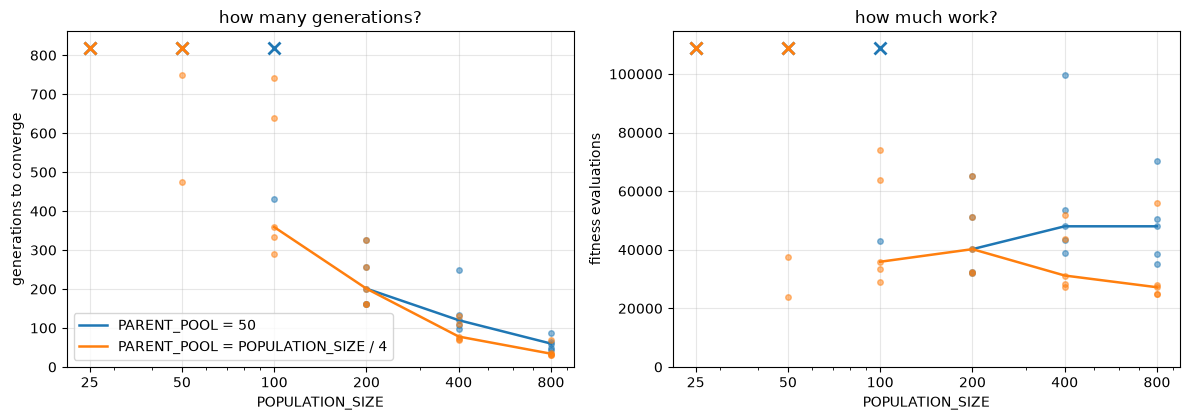

In [9]:
if not POP_SIZES:
    print("Not yet: choose the values to test in POP_SIZES (exercise cell above).")
else:
    print("PARENT_POOL = 50:")
    fixed = scan("POPULATION_SIZE", POP_SIZES)
    print("PARENT_POOL = POPULATION_SIZE / 4:")
    scaled = scan("POPULATION_SIZE", POP_SIZES, pool_fraction=0.25)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    for ax, y in zip(axes, ("generations", "evaluations")):
        plot_scan(ax, fixed, "PARENT_POOL = 50", "tab:blue", y=y)
        plot_scan(ax, scaled, "PARENT_POOL = POPULATION_SIZE / 4", "tab:orange", y=y)
        ax.set_xscale("log"); ax.set_xticks(POP_SIZES, [str(p) for p in POP_SIZES])
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.set_xlabel("POPULATION_SIZE")
    axes[0].legend()
    axes[0].set_title("how many generations?"); axes[1].set_title("how much work?")
    plt.tight_layout(); plt.show()

**Questions**

**(a1)** How does the number of generations change with the population size?

**(a2)** And the number of fitness evaluations, i.e. the real amount of work? Is a large population
"faster"?

**(a3)** With `PARENT_POOL = 50`, why do small populations not converge at all? (Look at how parents
are chosen in `run_ga`, section 4.)

<details open>
<summary><b>(a) population size — answers</b></summary>

Values used: `POP_SIZES = [25, 50, 100, 200, 400, 800]` (medians over seeds 1–5).

**(a1)** Larger populations need far fewer generations. With the parent pool scaled to a quarter of the
population: 359 generations at 100 individuals, 201 at 200, 78 at 400 and 34 at 800. With `PARENT_POOL = 50`
fixed: 201, 120 and 60 generations at 200, 400 and 800. A larger population tries more strings per
generation, so a correct letter turns up sooner at every position. Populations of 25 and 50 do not
converge within 1000 generations: with so few individuals there is too little diversity.

**(a2)** Not really. The number of fitness evaluations hardly changes: ≈27 000–40 000 with the
scaled parent pool and ≈40 000–48 000 with `PARENT_POOL = 50`, for 100 to 800 individuals. A large
population needs fewer *generations*, but each generation costs more. This only saves time when the
fitness of a generation is evaluated in parallel, e.g. on many processors. Compare this with the
search space in the theory section: ≈$2 \times 10^{100}$ strings, of which the GA looks at a few tens of thousands.
The seed-to-seed scatter is large (often a factor 2), which is why one run per setting is not enough.

**(a3)** Parents are drawn with `random.choice(population[:PARENT_POOL])`. When the population is not
larger than `PARENT_POOL` (25 or 50 individuals), this is the *whole* population: the fittest are no
more likely to reproduce than the worst, so there is **no selection**. Only the 2–5 elite strings keep the best
solution, and the population does not improve. At 100 individuals, half of the population is a parent:
the selection is weak and 4 of the 5 runs do not converge. What matters is not `PARENT_POOL` itself but
the fraction of the population allowed to reproduce.
</details>

### (b) Mutation rate

   MUTATION_RATE   generations (seeds 1-5)          median   evaluations


             0.0      ×     ×     ×     ×     ×           -             -


            0.01    286   199   250   395   334         286        57,200


            0.02    163   242   293   186   252         242        48,400


            0.05    161   162   326   201   256         201        40,200


             0.1      ×     ×     ×   297     ×           -             -


             0.2      ×     ×     ×     ×     ×           -             -



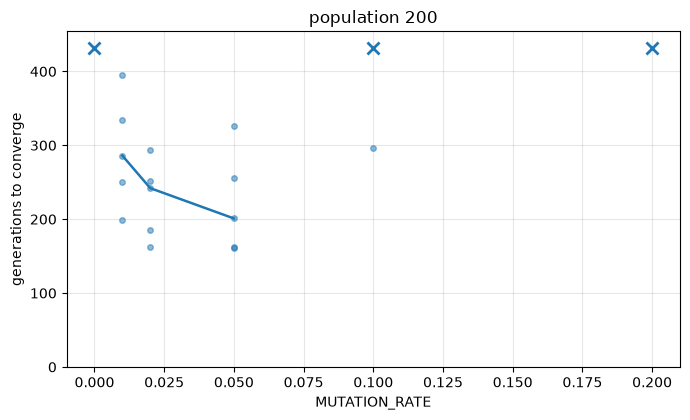

In [10]:
if not MUTATION_RATES:
    print("Not yet: choose the values to test in MUTATION_RATES (exercise cell above).")
else:
    res = scan("MUTATION_RATE", MUTATION_RATES)
    fig, ax = plt.subplots(figsize=(7, 4.3))
    plot_scan(ax, res, "median", "tab:blue")
    ax.set_xlabel("MUTATION_RATE"); ax.set_title(f"population {POPULATION_SIZE}")
    plt.tight_layout(); plt.show()

**Questions**

**(b1)** What happens without mutation (`MUTATION_RATE = 0`)? Why? (Think of what crossover can and
cannot do.)

**(b2)** Which mutation rate converges fastest? What goes wrong when it is too high? Compare with
the theory section ("The role of the mutation rate").

**(b3)** Look at `best_fit` in section 5: in which phase of the run does a high mutation rate cost
the most time?

<details open>
<summary><b>(b) mutation rate — answers</b></summary>

Values used: `MUTATION_RATES = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]`.

**(b1)** Without mutation the GA never converges. Crossover only copies characters that are already in
the population, at the same position: a letter that no individual has at a given position can never
appear there. In the random start population of 200 strings, a given position lacks the correct
letter with probability $(84/85)^{200} \approx 0.09$, so ≈5 of the 52 positions start without it, and
selection removes even more letters. Mutation is the only source of new letters.

**(b2)** 0.05 is the fastest of the tested values (median 201 generations; 0.02: 242; 0.01: 286). At
0.10 only 1 of the 5 runs converges within 1000 generations (the theory section quotes ≈1000–3000), and
at 0.20 none. The reason is that mutation mostly *destroys*: a mutated position gets the right letter
with probability only 1/85. A child of two (almost) perfect parents receives on average
$52 \times 0.10 \times 84/85 \approx 5$ new errors at a rate of 0.10, and is error-free with probability
only 0.4 % (7 % at 0.05, 60 % at 0.01). Too little mutation: new letters appear too slowly. Too much:
correct letters are destroyed faster than selection can keep them.

**(b3)** In the **tail**, when only a few letters are still wrong. Then nearly every mutation
damages a good string, while the last letters still need a lucky mutation to appear.
</details>

### (c) Selection pressure: parent pool and elitism

Two parameters decide how strongly the fittest individuals are favoured: parents are drawn from the
`PARENT_POOL` best individuals, and the `ELITE_FRAC` best are copied unchanged into the next
generation.

     PARENT_POOL   generations (seeds 1-5)          median   evaluations


               2    257   361   568   638   431         431        86,200


              10    240   280   460   284   265         280        56,000


              25    174   190   225   204   721         204        40,800


              50    161   162   326   201   256         201        40,200


             100    551   812   240     ×     ×         812       162,400


... (2 outputs left out)

            0.02    172   122   217   241   134         172        34,400


             0.1    161   162   326   201   256         201        40,200


            0.25    185   321   216   264   188         216        43,200


             0.5    496   481   685   461   626         496        99,200



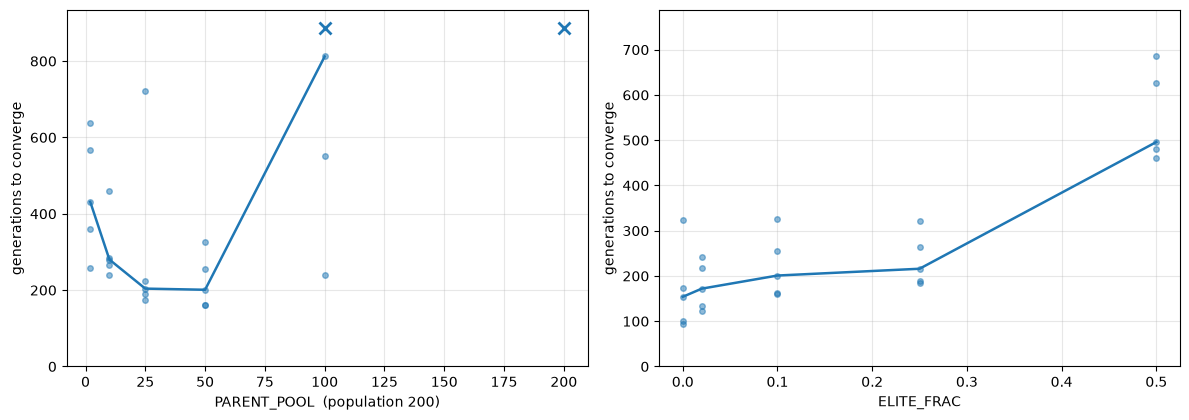

In [11]:
if not (PARENT_POOLS and ELITE_FRACS):
    print("Not yet: choose the values to test in PARENT_POOLS and ELITE_FRACS (exercise cell above).")
else:
    pools = scan("PARENT_POOL", PARENT_POOLS)
    elites = scan("ELITE_FRAC", ELITE_FRACS)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    plot_scan(axes[0], pools, "median", "tab:blue")
    axes[0].set_xlabel(f"PARENT_POOL  (population {POPULATION_SIZE})")
    plot_scan(axes[1], elites, "median", "tab:blue")
    axes[1].set_xlabel("ELITE_FRAC")
    plt.tight_layout(); plt.show()

**Questions**

**(c1)** What happens when `PARENT_POOL` equals the population size? And when it is very small?
Explain both ends with the words *selection* and *diversity*.

**(c2)** Elitism guarantees that the best string is never lost. Does a large elite fraction help?
What does it take away from each generation?

<details open>
<summary><b>(c) selection pressure — answers</b></summary>

Values used: `PARENT_POOLS = [2, 10, 25, 50, 100, 200]`, `ELITE_FRACS = [0.0, 0.02, 0.10, 0.25, 0.50]`.

**(c1)** `PARENT_POOL = 200` (the whole population) means **no selection**: the GA never converges.
At 100, selection is weak: 2 of the 5 runs do not converge and the median is 812 generations. A very
small pool (2) is **too much selection**: all children come from the same two parents, the
population loses its **diversity** and progress relies on mutation alone (median 431). The best values
(25–50, i.e. the best 12–25 % of the population) balance the two: enough selection to keep good
letters, enough diversity to combine them.

**(c2)** No. Up to 25 % the elite makes little difference (medians 154–216 generations, within the
scatter between seeds; here it was even fastest without any elite). With half of the population copied
unchanged (0.5) the GA becomes much slower (496): each generation then produces only half as many new
children, i.e. half as many new trials. Elitism protects the best solution, but every elite slot is a
child that is not made. In this problem the best string is rarely lost anyway, because its genes are
spread over many parents in the pool.
</details>

### (d) Swap mutation

       SWAP_RATE   generations (seeds 1-5)          median   evaluations


             0.0    161   162   326   201   256         201        40,200


             0.3    238   265   242   279   204         242        48,400


             1.0    162   266   257   315     ×         266        53,200



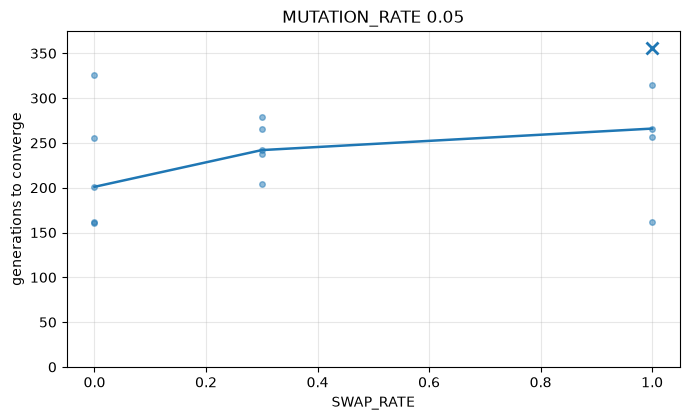

In [12]:
if not SWAP_RATES:
    print("Not yet: choose the values to test in SWAP_RATES (exercise cell above).")
else:
    res = scan("SWAP_RATE", SWAP_RATES)
    fig, ax = plt.subplots(figsize=(7, 4.3))
    plot_scan(ax, res, "median", "tab:blue")
    ax.set_xlabel("SWAP_RATE"); ax.set_title(f"MUTATION_RATE {MUTATION_RATE}")
    plt.tight_layout(); plt.show()

**Questions**

**(d1)** Does swap mutation speed up the search for this problem? Explain with the theory section
("Swap mutation").

**(d2)** (No scan needed.) For which kind of problem would you expect swap mutation to be essential?

<details open>
<summary><b>(d) swap mutation — answers</b></summary>

Values used: `SWAP_RATES = [0.0, 0.3, 1.0]`.

**(d1)** No, it slows it down (median 201 → 242 → 266 generations, and one run at 1.0 does not
converge within 1000). The target fixes *which letter goes where*. A swap moves two letters, so in an
almost correct string it usually turns two correct positions into two wrong ones. It only helps when
the right letter happens to sit at a wrong position, which is rare.

**(d2)** In **permutation problems**, where a solution is an ordering of a fixed set of items, e.g. the
order of the cities in the travelling-salesman problem. Each item must then appear exactly once: point
mutation would create duplicates, while a swap always gives a valid solution.
</details>

### Summary

Which parameters decide *whether* the GA converges, and which only *how fast*? What is the trade-off behind each of them?

<details open>
<summary><b>Summary — answers</b></summary>

* **Mutation rate and selection pressure decide whether the GA converges at all.** Without
  mutation, without selection (all individuals are parents) or with too much mutation, it does not
  find the target; with weak selection (half of the population are parents) it often fails.
* **Population size trades generations for work per generation.** The total number of fitness
  evaluations stays roughly the same (≈27 000–48 000 for 100–800 individuals), as long as the
  selection pressure is kept the same.
* Every parameter balances **exploration** (diversity: mutation, large parent pool, large population)
  against **exploitation** (selection: small parent pool, elitism). The best settings lie in between,
  and they depend on the problem: what works here (0.05, a quarter of the population as parents) must be
  re-tuned for another target or fitness function.
* A GA is random: compare settings over several seeds, never with a single run.
</details>